# Problema do Caixeiro-Viajante com Algoritmo Genético

## 1. Preparação dos dados

Importamos as bibliotecas necessárias e carregamos as coordenadas das cidades a partir do arquivo `cidades.mat`.

In [73]:
import numpy as np
from math import cos, hypot, pi, sin

# Carrega as coordenadas (x, y) de cada cidade.
x, y = np.loadtxt('cidades.mat')


## 2. Avaliação e população inicial

Cada rota recebe um custo correspondente à distância total percorrida, incluindo o retorno à cidade inicial. Em seguida, é criada uma população de rotas aleatórias ordenada pelo custo.

In [74]:
def custo_rotas(populacao, x, y):
    """Calcula o custo de cada rota, incluindo a volta à origem."""
    if len(x) != len(y):
        raise ValueError('x e y devem ter a mesma quantidade de cidades')

    custos = []
    for rota in populacao:
        if len(rota) == 0:
            custos.append(0.0)
            continue

        rota_fechada = [*rota, rota[0]]
        custo = 0.0

        for origem, destino in zip(rota_fechada, rota_fechada[1:]):
            try:
                distancia_x = x[origem - 1] - x[destino - 1]
                distancia_y = y[origem - 1] - y[destino - 1]
            except IndexError as exc:
                raise ValueError('a rota contém uma cidade inexistente') from exc

            custo += hypot(distancia_x, distancia_y)
        custos.append(custo)

    return custos

def criar_populacao_ordenada(x, y, tamanho_populacao=20, seed=None):
    """Cria rotas aleatórias e as ordena do maior para o menor custo."""
    gerador = np.random.default_rng(seed)
    cidades = np.arange(1, len(x) + 1)

    populacao = np.array([gerador.permutation(cidades) for _ in range(tamanho_populacao)])
    custos = np.array(custo_rotas(populacao, x, y))

    ordem = np.argsort(custos)[::-1]
    return populacao[ordem], custos[ordem]


## 3. Seleção dos pais

As melhores rotas seguem para a seleção por roleta. Rotas com custo menor têm mais chances de serem escolhidas para formar casais.

In [75]:
def selecionar_casais_roleta(melhores_rotas, melhores_custos, quantidade_casais=5, seed=None):
    """Seleciona casais por roleta com pesos lineares de 10 até 1."""
    ordem_melhor_para_pior = np.argsort(melhores_custos)
    rotas_ordenadas = melhores_rotas[ordem_melhor_para_pior]
    custos_ordenados = melhores_custos[ordem_melhor_para_pior]

    pesos = np.arange(len(rotas_ordenadas), 0, -1)
    roleta = np.repeat(np.arange(len(rotas_ordenadas)), pesos)

    gerador = np.random.default_rng(seed)
    indices_sorteados = gerador.choice(roleta, size=quantidade_casais * 2, replace=True)

    casais = rotas_ordenadas[indices_sorteados].reshape(quantidade_casais, 2, -1)
    custos_casais = custos_ordenados[indices_sorteados].reshape(quantidade_casais, 2)
    return roleta, casais, custos_casais


def criar_grafico_pizza_selecao(quantidade_pais=10):
    '''Mostra a probabilidade de seleção dos dez melhores pais.'''
    pesos = np.arange(quantidade_pais, 0, -1)
    probabilidades = pesos / pesos.sum()
    cores = ['#2563eb', '#0ea5e9', '#14b8a6', '#22c55e', '#84cc16', '#eab308', '#f97316', '#ef4444', '#ec4899', '#8b5cf6']
    cx, cy, raio = 260, 210, 145
    inicio = -pi / 2
    fatias, legenda = [], []

    for indice, probabilidade in enumerate(probabilidades):
        fim = inicio + 2 * pi * probabilidade
        x1, y1 = cx + raio * cos(inicio), cy + raio * sin(inicio)
        x2, y2 = cx + raio * cos(fim), cy + raio * sin(fim)
        cor = cores[indice % len(cores)]
        fatias.append(f'<path d="M {cx},{cy} L {x1:.1f},{y1:.1f} A {raio},{raio} 0 {int(fim - inicio > pi)},1 {x2:.1f},{y2:.1f} Z" fill="{cor}" stroke="white" stroke-width="2"/>')
        legenda.append(f'<rect x="455" y="{70 + indice * 28}" width="16" height="16" fill="{cor}"/><text x="480" y="{83 + indice * 28}" font-size="14">Pai {indice + 1}: {probabilidade:.1%}</text>')
        inicio = fim

    return f'''<svg xmlns="http://www.w3.org/2000/svg" width="760" height="420" viewBox="0 0 760 420">
<rect width="100%" height="100%" fill="white"/>
<text x="380" y="32" text-anchor="middle" font-size="20">Probabilidade de seleção dos 10 pais</text>
<text x="380" y="55" text-anchor="middle" font-size="13">Pai 1 representa a rota de menor custo entre os selecionados</text>
{''.join(fatias)}{''.join(legenda)}
</svg>'''


def exibir_grafico_pizza_selecao():
    """Exibe separadamente as chances da roleta dos dez pais."""
    from IPython.display import SVG, display

    display(SVG(criar_grafico_pizza_selecao()))


### Visualização da seleção

O gráfico mostra as probabilidades da roleta para os dez pais: a melhor rota recebe o maior peso.

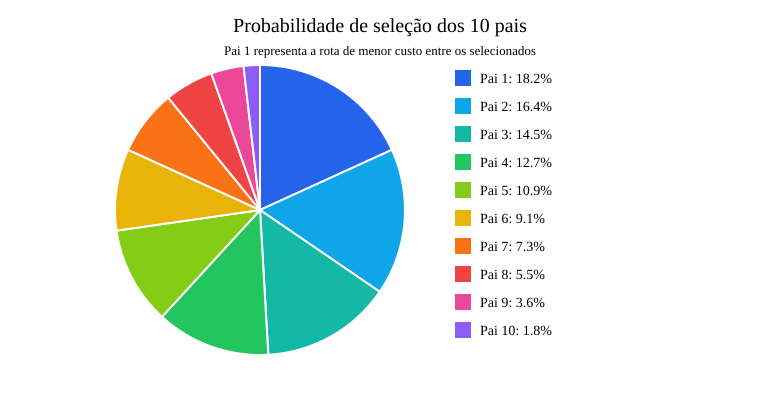

In [76]:
exibir_grafico_pizza_selecao()


In [77]:
def cruzar_casais_cycle(casais, seed=None):
    """Aplica cycle crossover a cada casal, preservando cidades sem repetição."""
    gerador = np.random.default_rng(seed)
    descendentes = np.empty_like(casais)

    for indice_casal, (pai_1, pai_2) in enumerate(casais):
        filho_1 = pai_1.copy()
        filho_2 = pai_2.copy()
        indice_por_cidade = {int(cidade): indice for indice, cidade in enumerate(pai_1)}

        inicio = gerador.integers(len(pai_1))
        indice = inicio
        while True:
            filho_1[indice] = pai_2[indice]
            filho_2[indice] = pai_1[indice]

            indice = indice_por_cidade[int(pai_2[indice])]
            if indice == inicio:
                break

        descendentes[indice_casal] = [filho_1, filho_2]

    return descendentes

def mutar_descendentes(descendentes, seed=None):
    """Troca duas cidades aleatórias em cada descendente."""
    gerador = np.random.default_rng(seed)
    descendentes_mutados = descendentes.copy()

    for casal in descendentes_mutados:
        for filho in casal:
            posicao_1, posicao_2 = gerador.choice(len(filho), size=2, replace=False)
            filho[posicao_1], filho[posicao_2] = filho[posicao_2], filho[posicao_1]

    return descendentes_mutados


## 5. Evolução da população

A cada geração, as dez melhores rotas são preservadas e completadas por dez descendentes mutados. O histórico guarda o melhor custo encontrado em cada geração.

In [78]:
def executar_algoritmo_genetico(
    x, y, numero_iteracoes=10_000, seed=None, intervalo_atualizacao=None, pausa_atualizacao=0.05
):
    """Evolui uma população com 10 pais preservados e 10 filhos por geração."""
    gerador = np.random.default_rng(seed)
    populacao, custos = criar_populacao_ordenada(
        x, y, tamanho_populacao=20, seed=gerador.integers(0, 2**32 - 1)
    )
    historico_melhor_custo = [custos[-1]]
    atualizadores = None

    for geracao in range(numero_iteracoes):
        melhores_rotas = populacao[-10:]
        melhores_custos = custos[-10:]

        _, casais, _ = selecionar_casais_roleta(
            melhores_rotas, melhores_custos, quantidade_casais=5,
            seed=gerador.integers(0, 2**32 - 1)
        )
        descendentes = cruzar_casais_cycle(casais, seed=gerador.integers(0, 2**32 - 1))
        filhos_mutados = mutar_descendentes(descendentes, seed=gerador.integers(0, 2**32 - 1))

        populacao = np.vstack((melhores_rotas, filhos_mutados.reshape(10, 20)))
        custos = np.array(custo_rotas(populacao, x, y))
        ordem = np.argsort(custos)[::-1]
        populacao = populacao[ordem]
        custos = custos[ordem]
        historico_melhor_custo.append(custos[-1])

        if intervalo_atualizacao and (geracao + 1) % intervalo_atualizacao == 0:
            from IPython.display import SVG, display
            from time import sleep

            grafico_evolucao, grafico_rota = criar_graficos_svg(
                historico_melhor_custo, x, y, populacao[-1]
            )
            if atualizadores is None:
                atualizadores = (
                    display(SVG(grafico_evolucao), display_id=True),
                    display(SVG(grafico_rota), display_id=True),
                )
            else:
                atualizadores[0].update(SVG(grafico_evolucao))
                atualizadores[1].update(SVG(grafico_rota))

            print(f'Geração {geracao + 1}: melhor custo = {custos[-1]:.3f}')
            sleep(pausa_atualizacao)

    return populacao, custos, historico_melhor_custo


## 6. Visualização

Os gráficos mostram a evolução do melhor custo e o caminho correspondente à melhor rota encontrada.

In [79]:
def criar_graficos_svg(historico_melhor_custo, x, y, melhor_rota):
    """Cria gráficos SVG da evolução do custo e da melhor rota."""
    largura, altura, margem = 760, 380, 55
    valores = np.asarray(historico_melhor_custo, dtype=float)
    minimo, maximo = valores.min(), valores.max()
    escala_y = maximo - minimo or 1
    escala_x = max(len(valores) - 1, 1)

    pontos_evolucao = ' '.join(
        f'{margem + i * (largura - 2 * margem) / escala_x:.1f},'
        f'{altura - margem - (valor - minimo) * (altura - 2 * margem) / escala_y:.1f}'
        for i, valor in enumerate(valores)
    )
    grafico_evolucao = f'''<svg xmlns="http://www.w3.org/2000/svg" width="{largura}" height="{altura}" viewBox="0 0 {largura} {altura}">
<rect width="100%" height="100%" fill="white"/>
<text x="{largura / 2}" y="28" text-anchor="middle" font-size="20">Evolução do melhor custo</text>
<line x1="{margem}" y1="{altura - margem}" x2="{largura - margem}" y2="{altura - margem}" stroke="black"/>
<line x1="{margem}" y1="{margem}" x2="{margem}" y2="{altura - margem}" stroke="black"/>
<polyline points="{pontos_evolucao}" fill="none" stroke="#2563eb" stroke-width="2"/>
<text x="{largura / 2}" y="{altura - 12}" text-anchor="middle">Geração</text>
<text x="15" y="{altura / 2}" transform="rotate(-90 15 {altura / 2})" text-anchor="middle">Melhor custo</text>
<text x="{margem}" y="{altura - margem + 20}" text-anchor="middle">0</text>
<text x="{largura - margem}" y="{altura - margem + 20}" text-anchor="middle">{len(valores) - 1}</text>
<text x="{margem - 8}" y="{margem}" text-anchor="end">{maximo:.3f}</text>
<text x="{margem - 8}" y="{altura - margem}" text-anchor="end">{minimo:.3f}</text>
</svg>'''

    menor_x, maior_x = np.min(x), np.max(x)
    menor_y, maior_y = np.min(y), np.max(y)
    alcance_x = maior_x - menor_x or 1
    alcance_y = maior_y - menor_y or 1

    def ponto_svg(indice):
        posicao_x = margem + (x[indice] - menor_x) * (largura - 2 * margem) / alcance_x
        posicao_y = altura - margem - (y[indice] - menor_y) * (altura - 2 * margem) / alcance_y
        return posicao_x, posicao_y

    rota_fechada = np.append(melhor_rota, melhor_rota[0]) - 1
    pontos_rota = ' '.join(f'{ponto_svg(indice)[0]:.1f},{ponto_svg(indice)[1]:.1f}' for indice in rota_fechada)
    cidades = ''.join(
        f'<circle cx="{ponto_svg(indice)[0]:.1f}" cy="{ponto_svg(indice)[1]:.1f}" r="5" fill="#dc2626"/>'
        f'<text x="{ponto_svg(indice)[0] + 8:.1f}" y="{ponto_svg(indice)[1] - 8:.1f}" font-size="12">{indice + 1}</text>'
        for indice in range(len(x))
    )
    grafico_rota = f'''<svg xmlns="http://www.w3.org/2000/svg" width="{largura}" height="{altura}" viewBox="0 0 {largura} {altura}">
<rect width="100%" height="100%" fill="white"/>
<text x="{largura / 2}" y="28" text-anchor="middle" font-size="20">Melhor rota encontrada</text>
<polyline points="{pontos_rota}" fill="none" stroke="#2563eb" stroke-width="2"/>{cidades}
<text x="{largura / 2}" y="{altura - 12}" text-anchor="middle">Coordenada x</text>
<text x="15" y="{altura / 2}" transform="rotate(-90 15 {altura / 2})" text-anchor="middle">Coordenada y</text>
</svg>'''
    return grafico_evolucao, grafico_rota

def exibir_graficos(*graficos):
    from IPython.display import SVG, display

    for grafico in graficos:
        display(SVG(grafico))


## 7. Execução do algoritmo

Defina a quantidade de gerações, execute o algoritmo e consulte a melhor solução encontrada.

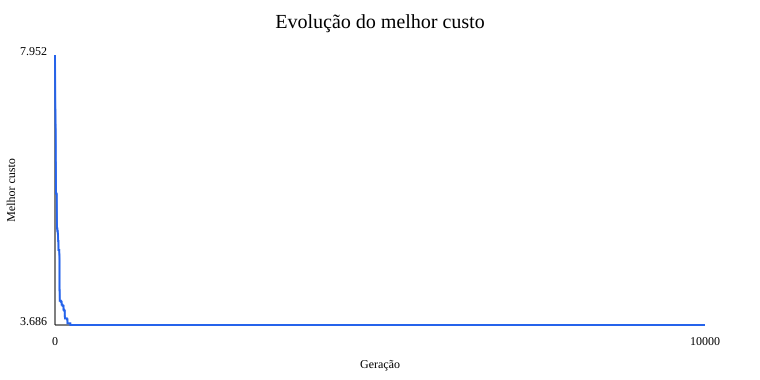

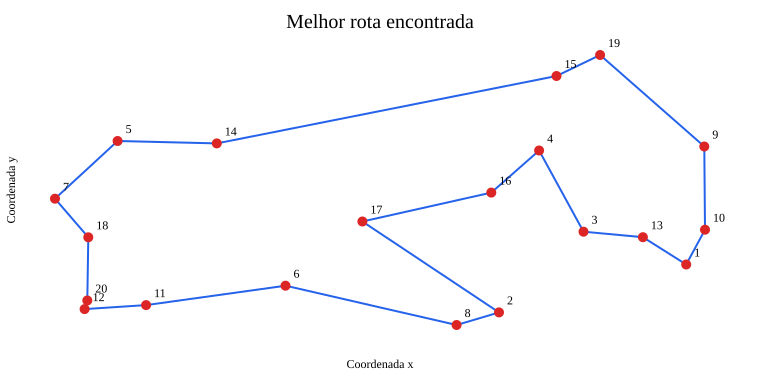

Geração 100: melhor custo = 4.052
Geração 200: melhor custo = 3.713
Geração 300: melhor custo = 3.686
Geração 400: melhor custo = 3.686
Geração 500: melhor custo = 3.686
Geração 600: melhor custo = 3.686
Geração 700: melhor custo = 3.686
Geração 800: melhor custo = 3.686
Geração 900: melhor custo = 3.686
Geração 1000: melhor custo = 3.686
Geração 1100: melhor custo = 3.686
Geração 1200: melhor custo = 3.686
Geração 1300: melhor custo = 3.686
Geração 1400: melhor custo = 3.686
Geração 1500: melhor custo = 3.686
Geração 1600: melhor custo = 3.686
Geração 1700: melhor custo = 3.686
Geração 1800: melhor custo = 3.686
Geração 1900: melhor custo = 3.686
Geração 2000: melhor custo = 3.686
Geração 2100: melhor custo = 3.686
Geração 2200: melhor custo = 3.686
Geração 2300: melhor custo = 3.686
Geração 2400: melhor custo = 3.686
Geração 2500: melhor custo = 3.686
Geração 2600: melhor custo = 3.686
Geração 2700: melhor custo = 3.686
Geração 2800: melhor custo = 3.686
Geração 2900: melhor custo = 

In [80]:
NUMERO_ITERACOES = 10_000
INTERVALO_ATUALIZACAO = 100
PAUSA_ATUALIZACAO = 0.05

populacao_final, custos_finais, historico_melhor_custo = executar_algoritmo_genetico(
    x, y, numero_iteracoes=NUMERO_ITERACOES,
    intervalo_atualizacao=INTERVALO_ATUALIZACAO,
    pausa_atualizacao=PAUSA_ATUALIZACAO
)

melhor_rota = populacao_final[-1]
melhor_custo = custos_finais[-1]

print(f'Melhor custo após {NUMERO_ITERACOES} gerações: {melhor_custo:.3f}')
print(f'Melhor rota: {melhor_rota}')

print('Visualização final atualizada na geração 10.000.')
